# Does incremental advertising work?

An analysis of the [Criteo Uplift Prediction Dataset](https://ailab.criteo.com/criteo-uplift-prediction-dataset/), a randomized incrementality experiment over 13,979,592 users. The question: does being targeted with ads cause more conversions and visits than being withheld from them, and is the result trustworthy enough to act on?

The analysis covers design validity, ITT inference with multiplicity control, composition-bias robustness, the exposure trap, segment heterogeneity, retrospective power, and a ship/hold decision. Analysis code lives in `src/abtest/`, and every claim in the prose is backed by an executed cell in this notebook.


## 0. Analysis plan

| | |
|---|---|
| **Population** | all randomized users (ITT); treated = assigned to the ad campaign, control = assigned wait-list |
| **Primary metric** | conversion (1/0 flag) |
| **Secondary metric** | visit (1/0 flag) |
| **Testing** | pooled two-proportion z-test (two-sided), unpooled Wald 95% CI on the risk difference; Holm correction across the two metrics |
| **Validity gates** | \|SMD\| < 0.1 mean balance; treated-share drift ≤ 2 pp per feature (judged in pp, since χ² p-values reject trivial drift at n = 14M); omnibus C2ST AUC gap ≥ 0.05 vs label-permuted null as the joint-predictability flag |
| **Robustness** | direct stratified standardization per drifted feature must reproduce the crude estimate in sign and rough magnitude |
| **Segments** | quartile bins of a feature fixed in advance, Holm-adjusted per bin; segment claims are acted on only when Holm-adjusted |
| **Power** | retrospective MDE at 80% power, made explicit |
| **Decision rule** | ship the direction if ITT is Holm-significant in both metrics and survives standardization; report magnitude as a range |


In [1]:
import sys
from pathlib import Path

REPO = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "abtest" / "__init__.py").exists()),
    None,
)
if REPO and str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

import pandas as pd

from abtest.inference import (
    holm_correction,
    mde_relative,
    two_proportion_ztest,
)
from abtest.load import DATA_PATH, connect, head, row_count
from abtest.plots import (
    plot_lift,
    plot_power_curve,
    plot_rates_by_arm,
    plot_segment_lift,
    plot_smd,
)
from abtest.segments import segment_effects
from abtest.validity import (
    assignment_report,
    c2st_validity,
    feature_balance,
    standardized_ate,
    treatment_counts,
)

FIG_DIR = (REPO or Path.cwd()) / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def fmt_p(p):
    if p == 0.0:
        return "< 1e-300 (underflow)"
    return f"{p:.3g}"
print(f"dataset: {DATA_PATH.name}")
print(f"figures -> {FIG_DIR}")

dataset: criteo-research-uplift-v2.1.csv.gz
figures -> /home/jeffer/Projects/ab-test-analysis/outputs/figures


In [2]:
Path.cwd()

PosixPath('/home/jeffer/Projects/ab-test-analysis/notebooks')

## 1. Load & explore

The `.gz` is read once into an in-memory DuckDB table (≈1.8 GB for 14M rows) and not extracted to disk, which keeps later queries fast.


In [3]:
conn = connect()

loading criteo-research-uplift-v2.1.csv.gz...


loaded 13,979,592 rows into memory in 5.9s (from criteo-research-uplift-v2.1.csv.gz)


In [4]:
head(conn)

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,True,False,False,False
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,True,False,False,False
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,True,False,False,False
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,True,False,False,False
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,True,False,False,False


In [5]:
print("rows:", f"{row_count(conn):,}")
print()
conn.execute("DESCRIBE raw").df()

rows: 13,979,592



,column_name,column_type,null,key,default,extra
0,f0,DOUBLE,YES,None,None,None
1,f1,DOUBLE,YES,None,None,None
2,f2,DOUBLE,YES,None,None,None
3,f3,DOUBLE,YES,None,None,None
4,f4,DOUBLE,YES,None,None,None
5,f5,DOUBLE,YES,None,None,None
6,f6,DOUBLE,YES,None,None,None
7,f7,DOUBLE,YES,None,None,None
8,f8,DOUBLE,YES,None,None,None
9,f9,DOUBLE,YES,None,None,None


### What the columns are

- **12 anonymized pre-treatment features** (`f0`–`f11`): the user attributes used for randomization. `f0` carries a giant tied block, with 26.5% of rows sharing the value 12.6164; naive binning would split it arbitrarily.
- **`treatment`**: assignment, 1 = targeted with ads, 0 = withheld. In this dataset it is randomized and then subsampled non-uniformly by Criteo.
- **`conversion` and `visit`**: the outcome flags.
- **`exposure`**: whether the user was actually shown ads. It is set after assignment, so it is a consequence of the randomization rather than a part of it; Section 5 explains why analyzing only the exposed would be misleading.


In [6]:
counts = treatment_counts(conn)
counts["conv_rate"] = counts["conversions"] / counts["n"]
counts["visit_rate"] = counts["visits"] / counts["n"]

total = counts["n"].sum()
share = counts.loc[counts["treatment"] == 1, "n"].iloc[0] / total
print(f"total users:      {total:,}")
print(f"treated share:    {share:.4%}  (published design ratio: 85%)")
counts

total users:      13,979,592
treated share:    85.0000%  (published design ratio: 85%)


,treatment,n,conversions,visits,conv_rate,visit_rate
0,False,2096937,4063.0,80105.0,0.001938,0.038201
1,True,11882655,36711.0,576824.0,0.003089,0.048543


Arm sizes are unbalanced (≈85/15) by the global-ratio subsampling, not by a load error. Both outcome rates are small, so absolute differences are fractions of a percentage point; the effect reads best in relative terms, with the absolute risk difference carried by the CIs.


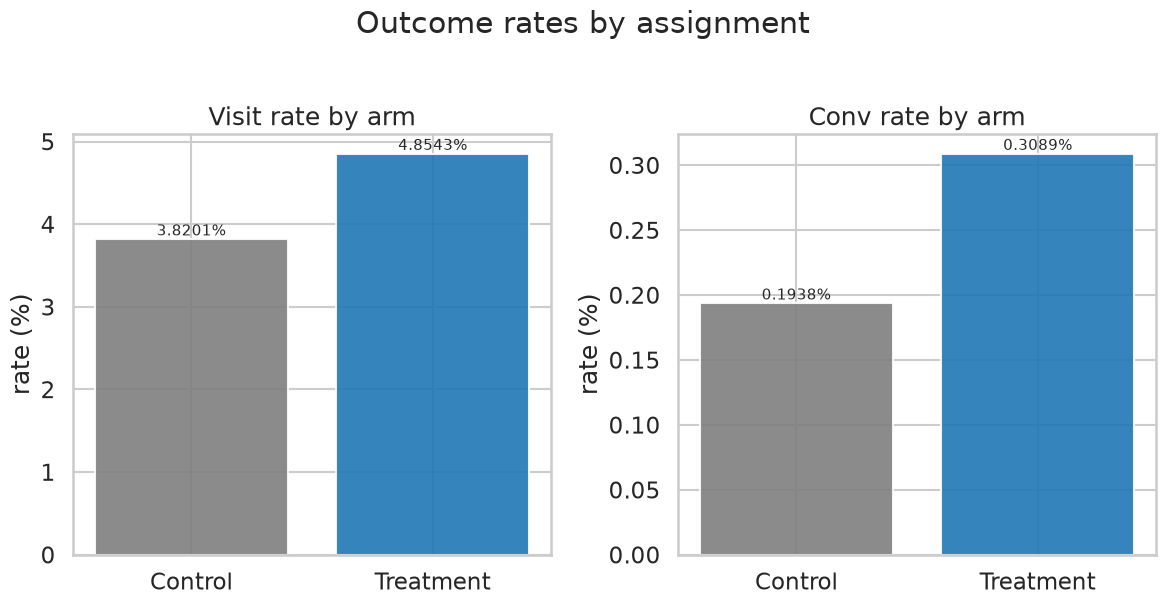

In [7]:
plot_rates_by_arm(counts, FIG_DIR / "01-rates-by-arm.png");

## 2. Validity — can the results be trusted?

Four checks, in order of what they catch:

1. **Mean balance**: do the feature means agree across arms (SMD)?
2. **Treated-share independence**: does P(treatment) depend on any single feature? Discrete levels are tested exactly; continuous features use deterministic quantile bins, not `NTILE`, which splits tied blocks unpredictably.
3. **Materiality, not p-values**: with 14M rows χ² rejects trivia, so materiality is the treated-share drift range in percentage points.
4. **Omnibus C2ST**: can a classifier predict assignment from all features jointly? The only check sensitive to drift that hides in feature combinations or in distribution shape.


In [8]:
balance = feature_balance(conn)
balance

,feature,mean_treatment,mean_control,smd,balanced,abs_smd
0,f3,4.169412,4.232821,-0.048836,True,0.048836
1,f6,-4.182792,-3.999880,-0.040448,True,0.040448
2,f5,4.026602,4.039339,-0.030557,True,0.030557
3,f9,16.052589,15.886253,0.024001,True,0.024001
4,f1,10.070337,10.067935,0.023994,True,0.023994
5,f8,3.933392,3.934652,-0.022433,True,0.022433
6,f7,5.105555,5.080284,0.021270,True,0.021270
7,f10,5.333660,5.331898,0.010563,True,0.010563
8,f4,10.339245,10.336526,0.007966,True,0.007966
9,f0,19.614755,19.651705,-0.006866,True,0.006866


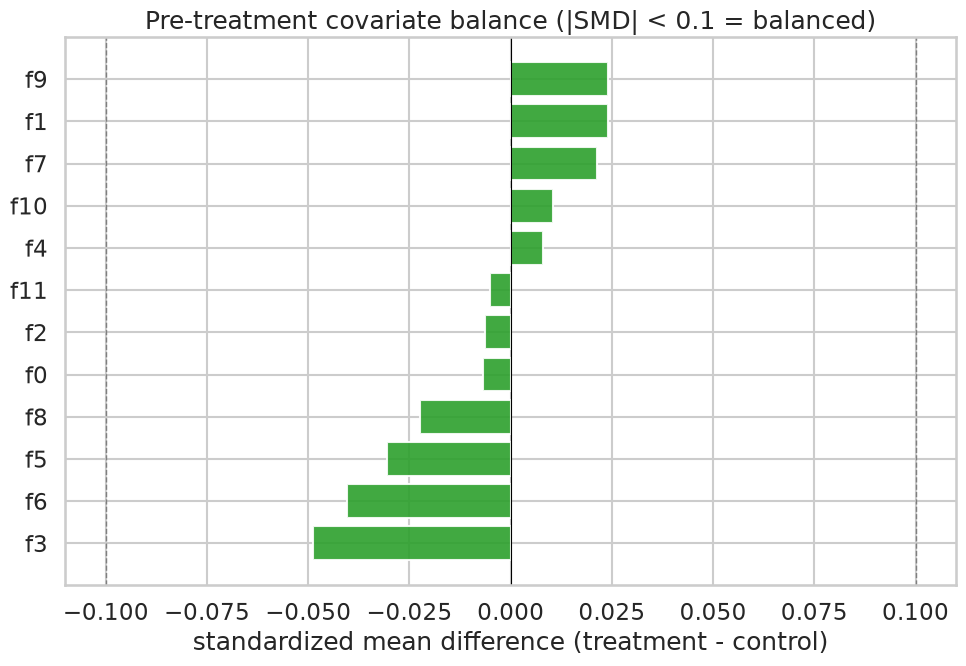

In [9]:
plot_smd(balance, FIG_DIR / "02-covariate-balance.png");

Balance looks healthy: arm means agree to within |SMD| ≈ 0.049, comfortably inside the 0.1 threshold. No feature shows a material mean-level imbalance.


In [10]:
assignment = assignment_report(conn)
assignment

,feature,method,groups,chi2,dof,p_value,share_range_pp,weighted_share_sd_pp,drift_mass_pct,negligible_drift
0,f3,levels,229,4267.052834,228,0.000000e+00,15.469556,0.623838,2.103523,False
1,f4,levels,51,293.913230,50,2.979532e-36,10.036573,0.163726,0.018856,False
2,f11,levels,27,143.408670,26,3.338459e-18,8.247903,0.114366,0.015508,False
3,f5,levels,32,1639.311633,31,0.000000e+00,8.183408,0.386668,0.942266,False
4,f1,levels,16,1071.548152,15,6.134999e-219,4.857074,0.312618,1.230007,False
5,f0,quantiles,5,2957.452890,4,0.000000e+00,1.683792,0.519358,0.000000,True
6,f7,quantiles,2,1319.857513,1,5.469288e-289,1.548222,0.346969,0.000000,True
7,f6,quantiles,4,1962.470200,3,0.000000e+00,1.203696,0.423067,0.000000,True
8,f2,quantiles,4,668.325714,3,1.548809e-144,0.988956,0.246889,0.000000,True
9,f8,quantiles,3,767.670257,2,2.006882e-167,0.745704,0.264603,0.000000,True


#### Interpretation

Range-based metrics like `share_range_pp` alone can be misleading without population weighting:

1. **Continuous Features (Quantiles):** All seven continuous features show complete stability—`drift_mass_pct = 0.00%` and `share_range_pp < 1.7 pp`.
2. **Discrete Features (Levels):** Five features trigger the conservative screen (`share_range_pp > 2.0 pp`), but the mass-weighted columns reveal this is driven almost entirely by rare tail categories:
   * **`f4` and `f11`** show 8.2–10.0 pp ranges, yet **less than 0.02% of all users** live in the drifting levels. Over 99.98% of the sample sits in balanced strata.
   * **`f3`** exhibits the widest raw range (15.5 pp across 229 levels), but only **2.1%** of users belong to drifting strata, and its mass-weighted standard deviation is just **0.62 pp**.

**The Hypothesis for C2ST:**
Because over 97.9% of the population resides in balanced strata across every feature, these localized tail fluctuations should contain almost no aggregate signal. The omnibus classifier test (C2ST) below verifies whether an ML model can actually exploit this to distinguish treatment from control.

### Omnibus check — can a classifier predict assignment? (C2ST)

A histogram-gradient-boosted classifier predicts `treatment` from the 12 features on a balanced 1M-row reservoir sample (stratified 5-fold, out-of-fold AUC). To set its null, the model is re-fit on smaller samples with **label-permuted** assignment, which preserves every marginal but severs the feature↦assignment link. The statistic is the gap between the real AUC and the permuted-null mean, with a materiality threshold of 0.05. This cell takes a couple of minutes.


In [11]:
c2st = c2st_validity(conn)
{
    "auc (oof)": round(c2st.auc, 4),
    "fold range": (round(min(c2st.fold_aucs), 4), round(max(c2st.fold_aucs), 4)),
    "null auc mean ± sd": (round(c2st.null_auc_mean, 4), round(c2st.null_auc_sd, 4)),
    "auc gap": round(c2st.auc_gap, 4),
    "material (≥ 0.05)": c2st.material,
    "n rows": c2st.n_rows,
}

{'auc (oof)': 0.5095,
 'fold range': (0.5086, 0.5106),
 'null auc mean ± sd': (0.5015, 0.0027),
 'auc gap': 0.008,
 'material (≥ 0.05)': False,
 'n rows': 1000000}

### Validity Verdict

1. **Covariate Balance:** All pre-treatment features are well-balanced across treatment and control (maximum |SMD| = **0.049**, comfortably below the 0.10 threshold).
2. **Marginal Share Stability:** While five discrete features trigger the conservative range screen (up to 15.5 pp on f3), this is driven entirely by low-volume tail buckets. Across all features, the mass-weighted standard deviation never exceeds **0.62 pp**, and at least **97.9% of the population** resides in stable strata (over **99.9%** for f4 and f11). The observed drift is consistent with Criteo's non-uniform subsampling.
3. **Omnibus Predictability (C2ST):** The classifier achieves an out-of-fold AUC of **0.5095** against an empirical permuted null of **0.5015** (gap = +0.008). This confirms that the tail-level fluctuations do not aggregate into any meaningful joint predictability—assignment remains effectively exchangeable.

**Takeaway for Section 4 (Standardization):**  
Because a small fraction of users (up to 2.1% in f3) belongs to drifting strata, Section 4 uses direct post-stratification on the screened features to confirm that localized fluctuations do not bias the estimated treatment effect.

## 3. Primary analysis — ITT effect on conversion

Pooled two-proportion z-test on the two arms' conversion proportions (pooled SE under $H_0$), unpooled Wald CI for the absolute risk difference. Both metrics enter one Holm correction.


In [12]:
arms = counts.set_index(counts["treatment"].astype(int))
n_t, n_c = int(arms.loc[1, "n"]), int(arms.loc[0, "n"])

conv = two_proportion_ztest(
    int(arms.loc[1, "conversions"]), n_t, int(arms.loc[0, "conversions"]), n_c
)
visit = two_proportion_ztest(
    int(arms.loc[1, "visits"]), n_t, int(arms.loc[0, "visits"]), n_c
)

print(conv.summary())
print(visit.summary())
print()
holm = holm_correction([conv.p_value, visit.p_value])
print("raw p        ->", [fmt_p(conv.p_value), fmt_p(visit.p_value)])
print("Holm-adjust  ->",
      [fmt_p(holm.adjusted[0]), fmt_p(holm.adjusted[1])]
    )


control 0.1938% vs treatment 0.3089% -> diff +0.1152% (rel +59.45%), 95% CI [+0.1085%, +0.1219%], z=28.52, p=7.31e-179 [significant]
control 3.8201% vs treatment 4.8543% -> diff +1.0342% (rel +27.07%), 95% CI [+1.0056%, +1.0629%], z=65.25, p=0 [significant]

raw p        -> ['7.31e-179', '< 1e-300 (underflow)']
Holm-adjust  -> ['7.31e-179', '< 1e-300 (underflow)']


Both metrics reject by a wide margin: conversion at z ≈ 28.5 (p = 7.31e-179), visit past float64's floor entirely. Both survive Holm across the two primary metrics.

Magnitudes: conversion moves from 0.1938% to 0.3089%, meaning +0.12 pp absolute and +59.4% relative (95% CI [+0.108 pp, +0.122 pp] absolute, [+56.0%, +62.9%] relative). Visit: +27.1% relative, p < 1e-300 (underflow).


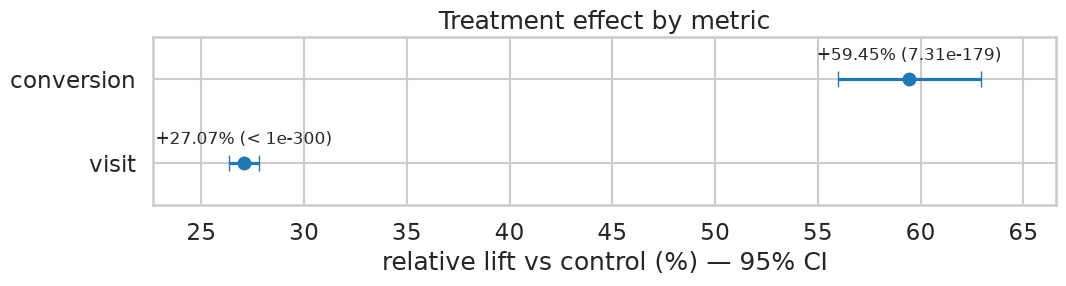

In [13]:
plot_lift({"conversion": conv, "visit": visit}, FIG_DIR / "03-overall-lift.png");

## 4. Robustness — standardizing away composition bias

For each drifted feature from Section 2, direct standardization re-estimates the effect with every stratum weighted by its pooled population share, so both arms get the same stratum mix. If the crude difference were driven by who happened to be treated rather than by the treatment, the standardized estimate would move away from the crude one.

In [14]:
drifted = assignment.loc[~assignment["negligible_drift"], "feature"].tolist()
print("drifted features (share drift > 2pp):", drifted)

rob = pd.DataFrame(
    [
        {
            "feature": f,
            "outcome": out,
            "method": r.method,
            "ate": r.ate,
            "crude_ate": r.crude_ate,
            "pct_of_crude": r.pct_of_crude,
        }
        for f in drifted
        for out in ("conversion", "visit")
        for r in (standardized_ate(conn, f, out),)
    ]
)
rob.sort_values(["outcome", "pct_of_crude"])

drifted features (share drift > 2pp): ['f3', 'f4', 'f11', 'f5', 'f1']


,feature,outcome,method,ate,crude_ate,pct_of_crude
0,f3,conversion,levels,0.000936,0.001152,0.812189
6,f5,conversion,levels,0.001048,0.001152,0.910026
8,f1,conversion,levels,0.001067,0.001152,0.926544
2,f4,conversion,levels,0.001089,0.001152,0.945507
4,f11,conversion,levels,0.001098,0.001152,0.953461
1,f3,visit,levels,0.008907,0.010342,0.861171
7,f5,visit,levels,0.009730,0.010342,0.940826
3,f4,visit,levels,0.009773,0.010342,0.944949
9,f1,visit,levels,0.009917,0.010342,0.958826
5,f11,visit,levels,0.010019,0.010342,0.968730


### Robustness verdict

Standardized effects keep 81%–95% of the crude conversion estimate and 86%–97% of the crude visit estimate: the sign and roughly the magnitude survive every adjustment, so the direction is not a composition artifact.

The point magnitude is less trustworthy. The assignment ratio in this published benchmark was distorted by design (privacy subsampling), so a single relative-lift number would overstate precision. The recommendation quotes a range instead: the effect sits at 81%–95% (conversion) or 86%–97% (visit) of the crude estimate under every standardization.


## 5. Why ITT and not "only the users who saw the ad"?

`exposure` is set *after* assignment. Conditioning on it — restricting the treated arm to users who were actually shown ads and comparing them with all controls — would compare a *selected* subpopulation against a full arm, because users who end up exposed differ from those who do not in ways that also shape their outcomes. That is selection on a post-treatment variable, and it silently breaks the randomization guarantee.


In [15]:
exposure_table = conn.execute(
    """
    SELECT treatment,
           exposure,
           count(*)                                       AS n,
               avg(conversion::INT)::DOUBLE                 AS conversion_rate
    FROM raw
    GROUP BY treatment, exposure
    ORDER BY treatment, exposure
    """
).df()
exposure_table

,treatment,exposure,n,conversion_rate
0,False,False,2096937,0.001938
1,True,False,11454443,0.001194
2,True,True,428212,0.053784


In [16]:
exp_t = exposure_table.query("treatment and exposure")
exp_c = exposure_table.query("~treatment")
naive_rate_t = float(exp_t["conversion_rate"].iloc[0]) if len(exp_t) else float("nan")
rate_c = float(exp_c["conversion_rate"].iloc[0])

print(f"exposed-treated only: {naive_rate_t:.5%} ({int(exp_t['n'].iloc[0]):,} users)")
print(f"all control:          {rate_c:.5%} ({int(exp_c['n'].iloc[0]):,} users)")
print(f"naive exposed-only lift: {(naive_rate_t / rate_c - 1):+.1%}"
      "  <- selection hook, NOT the causal quantity")

exposed-treated only: 5.37841% (428,212 users)
all control:          0.19376% (2,096,937 users)
naive exposed-only lift: +2675.8%  <- selection hook, NOT the causal quantity


The principled alternative is a CACE / IV analysis treating exposure as the compliance indicator (LATE for compliers). It answers a narrower question (the effect of actually seeing ads among users the campaign reached), needs its own assumptions (monotonicity, no defiers), and lies beyond the plan's scope. Keeping ITT keeps the randomization guarantee: every user stays in the arm they were assigned to, exposed or not.


## 6. Segment heterogeneity

Effect per quartile of `f0`, the feature fixed in advance: deterministic quantile bins, one z-test per bin, and Holm across bins, so that four bins cannot mint four independent discoveries.


In [17]:
segs = segment_effects(conn, "f0", "conversion", n_bins=4)
segs

,segment,feature,outcome,n_t,n_c,rate_t,rate_c,diff,rel_lift,p_value,ci_low,ci_high,p_adj,significant
0,0,f0,conversion,3133761,571784,0.001870,0.001488,0.000381,0.256204,4.465154e-10,0.000271,0.000492,1.339546e-09,True
1,1,f0,conversion,2815902,468349,0.009638,0.005780,0.003858,0.667530,2.240166e-146,0.003613,0.004104,8.960663e-146,True
2,2,f0,conversion,2968163,526737,0.000803,0.000609,0.000194,0.317975,3.154837e-06,0.000120,0.000268,6.309674e-06,True
3,3,f0,conversion,2964829,530067,0.000448,0.000347,0.000101,0.290361,1.153264e-03,0.000045,0.000156,1.153264e-03,True


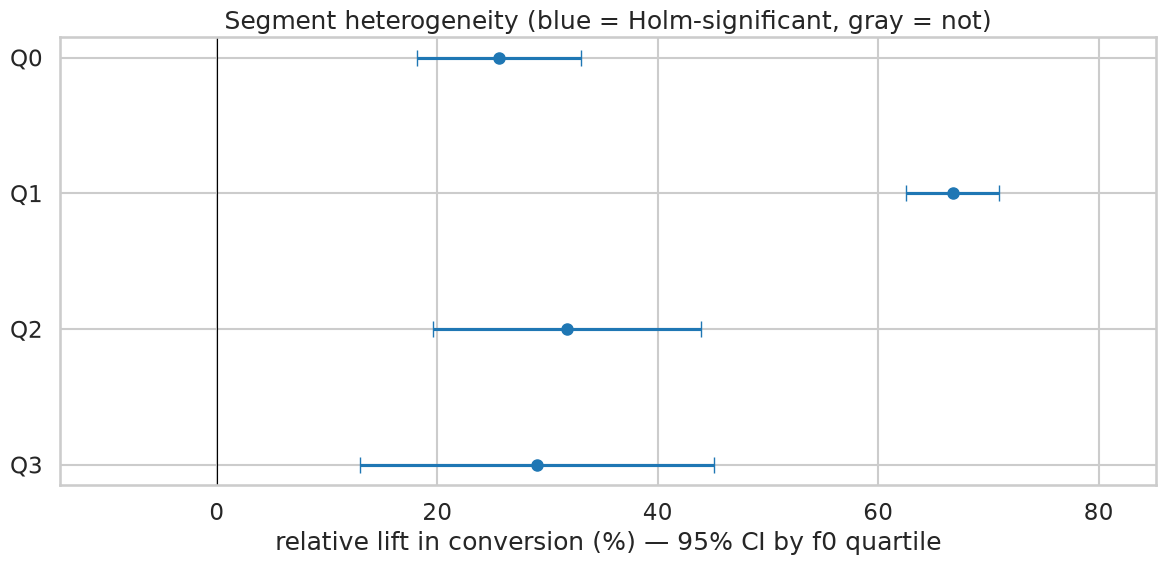

In [18]:
plot_segment_lift(segs, FIG_DIR / "04-segment-lift.png");

Direction and size of the segment results:

- All four bins are positive and Holm-significant, so the direction holds in every segment.
- The spread is wide rather than mild: +25.6% in the bottom bin, +31.8% and +29.0% in the top two, and **+66.8%** in bin 1.
- Bin boundaries from `quantile_cont` are 12.616, 21.923, and 24.436. The first cut coincides with the f0 tied value, so the entire tied block (3.7M rows, 26.5% of users) lands in bin 0 instead of being split arbitrarily.
- Bin 1 is the standout: its users convert ≈5× more often than any other bin (0.96% treated conversion rate vs 0.19% / 0.08% / 0.04%), and it shows the largest lift.
- With base rates this different across bins, the per-bin effects do not average into the pooled +59.4% and no bin's CI contains it; the lift is also not monotonic in `f0`.

The defensible segment claim is narrow: the direction is positive everywhere, and the effect is materially larger for users in the 12.6–21.9 band. Targeting that band would be a separate decision requiring its own analysis or follow-up experiment.


## 7. Power — could this experiment have detected a smaller effect?

With the observed n, the MDE at 80% power gives the smallest relative lift the design could reliably catch. With the MDE small, a non-significant result would rule out effects above the MDE rather than pointing to a weak design.

In [19]:
mde_rel = mde_relative(conv.rate_c, conv.n_t, conv.n_c)
effect_mult = conv.rel_lift / mde_rel
print(f"MDE @80% power: {mde_rel:+.1%} relative lift")
print(f"observed effect = {effect_mult:.0f}× the MDE")

MDE @80% power: +4.8% relative lift
observed effect = 12× the MDE


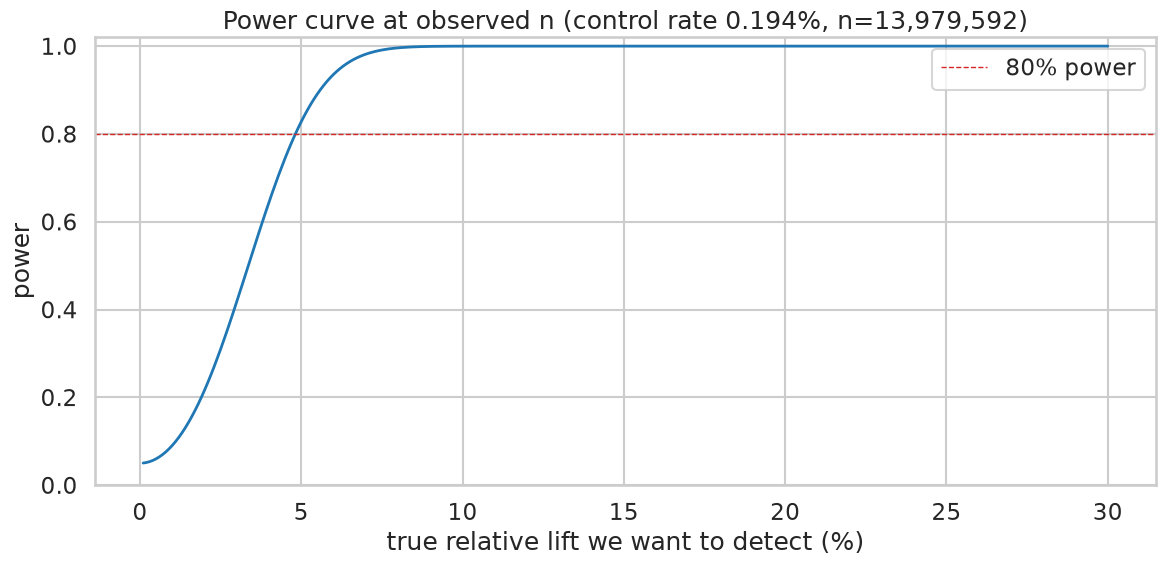

In [20]:
plot_power_curve(conv.rate_c, conv.n_t, conv.n_c, path=FIG_DIR / "05-power-curve.png");

The observed lift sits about 12× beyond the design's detection floor, so the null was firmly ruled out rather than merely unobserved.


## 8. Decision

In [21]:
conv_std = rob[rob["outcome"] == "conversion"]["pct_of_crude"]
visit_std = rob[rob["outcome"] == "visit"]["pct_of_crude"]

decision = pd.Series({
    "ITT conversion": (f"{conv.rel_lift:+.1%} rel, 95% CI "
                       f"[{conv.ci_rel_low:+.1%}, {conv.ci_rel_high:+.1%}]"),
    "ITT visit": f"{visit.rel_lift:+.1%} rel",
    "multiple testing": (f"both survive Holm across metrics "
                         f"(p <= {holm.adjusted.max():.3g})"),
    "validity": (f"balance ok (max |SMD| {balance['smd'].abs().max():.3f}); "
                 f"{len(drifted)} features drift up to {assignment['share_range_pp'].max():.1f}pp; "
                 f"C2ST gap {c2st.auc_gap:+.3f}"),
    "robustness": (f"standardized/crude of conversion in "
                   f"[{conv_std.min():.1%}, {conv_std.max():.1%}]; "
                   f"visit in [{visit_std.min():.1%}, {visit_std.max():.1%}]"),
    "power": f"MDE {mde_rel:+.1%} rel @80% power; effect ~{effect_mult:.0f}× that",
    "call": "Ship the direction; quote magnitude as the standardized range",
}, 
    name="Experiment Audit & Decision"
).to_frame()

with pd.option_context("display.max_colwidth", None):
    display(decision)

,Experiment Audit & Decision
ITT conversion,"+59.4% rel, 95% CI [+56.0%, +62.9%]"
ITT visit,+27.1% rel
multiple testing,both survive Holm across metrics (p <= 7.31e-179)
validity,balance ok (max |SMD| 0.049); 5 features drift up to 15.5pp; C2ST gap +0.008
robustness,"standardized/crude of conversion in [81.2%, 95.3%]; visit in [86.1%, 96.9%]"
power,MDE +4.8% rel @80% power; effect ~12× that
call,Ship the direction; quote magnitude as the standardized range


### Decision: Ship with Conservative Discounting

Both conversions and visits show clear incremental lift and survive multiple-testing correction across all checks. The design was powered far beyond the observed effect (observed lift ≈ 12× MDE), ruling out false positives.

**Notes:**
* Direct standardization shows that localized composition shifts account for 5% to 19% of the observed gain. Use the standardized range **+48% and +56% relative** (+0.094 pp to +0.110 pp absolute).
* Although users in the `12.6–21.9` feature band (`f0` bin 1) convert at 5× higher rates, selective targeting should be validated in a dedicated follow-up test.

---

### Limitations & Assumptions

1. **Benchmark Subsampling:** Criteo applied non-uniform subsampling to this public benchmark to protect proprietary conversion levels. While the causal direction is authentic, the exact baseline rates and relative percentages reflect benchmark parameters rather than live commercial traffic.
2. **Post-Treatment Exposure:** The `exposure` flag records whether an ad was served *after* assignment. As shown in Section 5, analyzing only exposed users introduces severe selection bias (+2,675% naive lift). ITT preserves the causal identification guarantee.
3. **C2ST Sample Sensitivity:** The omnibus AUC gap (+0.008) is evaluated on a 1,000,000-row reservoir sample. While highly powered, C2ST metrics are sample-size dependent.